# 03 · Churn Prediction (Machine Learning)

**Project:** E-Commerce Customer Segmentation & Retention (Python + SQL + ML)

### Business question
*Which customers are likely to stop buying in the next 90 days?* If I know this early, the business can contact them **before** they are lost.

### Setup (decided in SQL, `sql/05_churn_feature_engineering.sql`)
- **Churn definition:** no purchase in the 90 days after a cutoff date (supported by SQL query Q8: ~81% of re-orders happen within 90 days).
- **Features:** behaviour of each customer **before** the cutoff only (recency, frequency, spend, trends, returns...). No future information → no data leakage.
- **Training / test split by TIME:** train on the cutoff **2011-06-11** (label window Jun-Sep) and test on the **later** cutoff **2011-09-10** (label window Sep-Dec). This mimics real life: a model trained on the past must predict the future. A random split would be too optimistic.

## Step 0 · Setup

In [1]:
import sys
sys.path.append("../src")                      # so I can import my helper files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib                                  # saves a trained model to a file
from pathlib import Path

from sklearn.pipeline import make_pipeline                    # chains steps (impute -> scale -> model) into one object
from sklearn.impute import SimpleImputer                      # fills missing values
from sklearn.preprocessing import StandardScaler              # puts features on the same scale
from sklearn.dummy import DummyClassifier                     # a 'know-nothing' baseline to beat
from sklearn.linear_model import LogisticRegression           # simple, explainable classifier
from sklearn.ensemble import RandomForestClassifier           # more flexible tree-based classifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold   # hyper-parameter search with cross-validation
from sklearn.inspection import permutation_importance         # which features really matter?
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, precision_recall_curve)

from db_utils import read_sql_or_csv
from churn_utils import prepare_features, FEATURES            # my shared feature preparation

sns.set_theme(style="whitegrid", palette="deep")
pd.options.display.float_format = "{:,.3f}".format
RANDOM_STATE = 42
IMAGES, PROCESSED, MODELS, OUTPUTS = Path("../images"), Path("../data/processed"), Path("../models"), Path("../outputs")

## Step 1 · Load the features built by the SQL stored procedure
**What:** read `churn_features` (one row per customer per cutoff date). **Why:** SQL already did the heavy lifting; Python only models.

In [2]:
churn_all = read_sql_or_csv("SELECT * FROM churn_features", csv_fallback=PROCESSED / "churn_features.csv")
churn_all["cutoff_date"] = pd.to_datetime(churn_all["cutoff_date"])      # make sure dates are real dates (CSV gives text)

# rows per cutoff and churn rate (the last cutoff has no label because its future is unknown)
summary = churn_all.groupby("cutoff_date").agg(customers=("customer_id", "size"),
                                              labelled=("churned", "count"),     # count() ignores missing labels
                                              churn_rate=("churned", "mean"))
summary

Loaded from MySQL


,customers,labelled,churn_rate
cutoff_date,,,
2011-06-11,4951,4951,0.680
2011-09-10,5256,5256,0.565
2011-12-10,5852,0,NaN


**Evaluation:** the cutoff `2011-12-10` has **0 labelled rows** (its future has not happened) — correct, and I will use it later for real predictions. The churn rate is **68% / 57%**, which is high. Why? Because "customers who ever bought" includes many people who left long ago. I investigate that next.

## Step 2 · Who should be in the model? (a decision I tested)
A retention team contacts customers who are **still active**, not ones who left a year ago. If I include long-lapsed customers, the model gets easy points by saying *"silent for 400 days → will stay silent"*, which is correct but not useful.

I compare two populations: **all customers** vs **active customers** (last order ≤ 180 days before the cutoff).

In [3]:
train_all = churn_all[churn_all["cutoff_date"] == "2011-06-11"].copy()      # training period
test_all = churn_all[churn_all["cutoff_date"] == "2011-09-10"].copy()       # later test period

def quick_auc(train_df, test_df):
    # fit a simple logistic regression and return the ROC-AUC on the test period
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(prepare_features(train_df), train_df["churned"].astype(int))
    return roc_auc_score(test_df["churned"].astype(int), model.predict_proba(prepare_features(test_df))[:, 1])

rows = []
for name, tr, te in [("All customers", train_all, test_all),
                     ("Active (last order <= 180 days)", train_all[train_all["recency_days"] <= 180], test_all[test_all["recency_days"] <= 180])]:
    rows.append({"population": name, "train_rows": len(tr), "test_rows": len(te),
                 "test_churn_rate": te["churned"].mean(), "ROC_AUC": quick_auc(tr, te)})
pd.DataFrame(rows)

,population,train_rows,test_rows,test_churn_rate,ROC_AUC
0,All customers,4951,5256,0.565,0.796
1,Active (last order <= 180 days),2640,2783,0.382,0.758


**Evaluation:** on all customers the AUC looks better (~0.80) but a large part of that is the easy task of recognising people who are already gone. On the **active** population the AUC is lower (~0.76) — that is the **honest number for the real business problem**. 
**Decision:** use the **active population** from now on. (A model with 0.76 on a hard, relevant problem is more valuable than 0.80 on an easy, irrelevant one.)

In [4]:
# final train / test sets (active customers only)
train = train_all[train_all["recency_days"] <= 180].copy()
test = test_all[test_all["recency_days"] <= 180].copy()

X_train, y_train = prepare_features(train), train["churned"].astype(int)    # features + 0/1 label
X_test, y_test = prepare_features(test), test["churned"].astype(int)

print(f"Train: {len(train):,} customers, churn rate {y_train.mean():.1%}")
print(f"Test : {len(test):,} customers, churn rate {y_test.mean():.1%}")
print("\nMissing values per feature (train):")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train: 2,640 customers, churn rate 50.5%
Test : 2,783 customers, churn rate 38.2%

Missing values per feature (train):
avg_days_between_orders    433
dtype: int64


**Evaluation:** the churn rate **differs between periods** (about 51% in training vs 38% in test) because the test window covers the busy Sept–Dec season, when more customers come back. This is a real-world challenge (seasonal shift) and I must keep it in mind when reading probabilities. 
Only `avg_days_between_orders` has missing values — for customers with a single order there is no gap to average. I fill it with the **median** inside the pipeline (fitted on training data only, so nothing leaks from the test set).

## Step 3 · Quick look: do the features relate to churn?

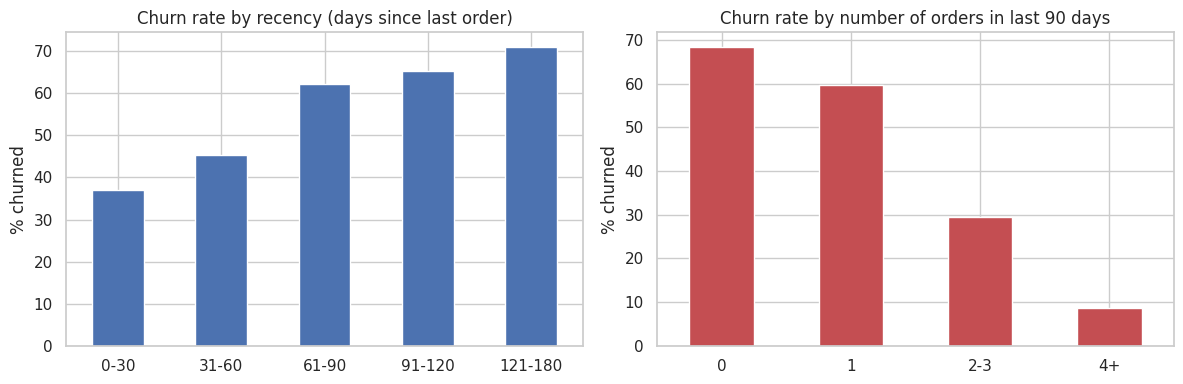

{'0-30': 37.1, '31-60': 45.3, '61-90': 62.3, '91-120': 65.2, '121-180': 70.9}
{'0': 68.3, '1': 59.7, '2-3': 29.5, '4+': 8.7}


In [5]:
# churn rate by recent activity and by recency bucket (training data)
tmp = train.copy()
tmp["recency_bucket"] = pd.cut(tmp["recency_days"], bins=[0, 30, 60, 90, 120, 180], labels=["0-30", "31-60", "61-90", "91-120", "121-180"])
rec = tmp.groupby("recency_bucket", observed=True)["churned"].mean() * 100            # % churned in each bucket

tmp["orders_bucket"] = pd.cut(tmp["orders_last_90d"], bins=[-1, 0, 1, 3, 1000], labels=["0", "1", "2-3", "4+"])
act = tmp.groupby("orders_bucket", observed=True)["churned"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rec.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn rate by recency (days since last order)")
axes[0].set_ylabel("% churned"); axes[0].set_xlabel("")
act.plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Churn rate by number of orders in last 90 days")
axes[1].set_ylabel("% churned"); axes[1].set_xlabel("")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(IMAGES / "14_churn_vs_recency_activity.png", dpi=150, bbox_inches="tight")
plt.show()
print(rec.round(1).to_dict()); print(act.round(1).to_dict())

**Insight:** churn rises with recency and falls strongly with recent activity: customers with 0 orders in the last 90 days churn far more often than customers with 4+ orders. This confirms the features carry real signal before I even fit a model.

## Step 4 · Models: from a baseline to a tuned model
I compare three models on the **future** test period:
1. **Dummy baseline** (always predicts the training churn rate) → the minimum to beat
2. **Logistic Regression** → simple, explainable (I studied it in my classification module)
3. **Random Forest** → can capture non-linear patterns

**Metrics (and why):**
- **ROC-AUC:** how well the model *ranks* risky customers above safe ones (0.5 = random, 1 = perfect). Not affected by the threshold.
- **PR-AUC (average precision):** like AUC but focused on the churn class; baseline = churn rate.
- **Precision / Recall / F1 at 0.5:** *precision* = of the customers flagged, how many really churn; *recall* = of all churners, how many did I catch.
- I do **not** use plain accuracy as the headline — it hides what matters when classes are not 50/50.

In [6]:
# helper that evaluates a fitted model on the test period and returns a dictionary of metrics
def evaluate(name, model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]                 # predicted churn probability for each customer
    pred = (proba >= threshold).astype(int)              # turn probability into a 0/1 decision
    return {"model": name,
            "ROC_AUC": roc_auc_score(y, proba),
            "PR_AUC": average_precision_score(y, proba),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred),
            "F1": f1_score(y, pred)}

# model 1: baseline
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)

# model 2: logistic regression pipeline (fill gaps -> scale -> fit)
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

# model 3: random forest (first with sensible default settings)
rf = make_pipeline(SimpleImputer(strategy="median"),
                   RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1))
rf.fit(X_train, y_train)

results = pd.DataFrame([evaluate("Dummy baseline", dummy, X_test, y_test),
                        evaluate("Logistic Regression", logreg, X_test, y_test),
                        evaluate("Random Forest (default)", rf, X_test, y_test)])
results

,model,ROC_AUC,PR_AUC,precision,recall,F1
0,Dummy baseline,0.500,0.382,0.382,1.000,0.553
1,Logistic Regression,0.758,0.631,0.541,0.781,0.639
2,Random Forest (default),0.758,0.625,0.540,0.789,0.641


**Evaluation:** both real models clearly beat the baseline (AUC 0.50 → ~0.76). Logistic Regression and Random Forest are **almost identical** — so the extra complexity of the forest buys nothing yet.

### Optimization: tune the Random Forest with cross-validation
**What:** `GridSearchCV` tries combinations of settings using 5-fold cross-validation **on the training data only** (the test period stays untouched). **Why:** to check honestly whether tuning lets the forest beat the simple model, without peeking at the test set.

In [7]:
# the settings I want to try (3 x 2 x 2 = 12 combinations)
param_grid = {
    "randomforestclassifier__n_estimators": [200, 400],        # number of trees
    "randomforestclassifier__max_depth": [4, 8, None],         # how deep each tree may grow (None = unlimited)
    "randomforestclassifier__min_samples_leaf": [5, 20],       # minimum customers in a leaf (bigger = simpler trees)
}
rf_base = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)    # keeps the churn share equal in every fold
grid = GridSearchCV(rf_base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)                                                   # trains 12 x 5 = 60 models

print("Best settings:", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
print(f"Best cross-validated AUC (on training data): {grid.best_score_:.3f}")
rf_tuned = grid.best_estimator_

# cross-validated AUC of the logistic regression for a fair comparison
from sklearn.model_selection import cross_val_score
lr_cv = cross_val_score(logreg, X_train, y_train, scoring="roc_auc", cv=cv).mean()
print(f"Logistic Regression cross-validated AUC (training data): {lr_cv:.3f}")

Best settings: {'max_depth': 8, 'min_samples_leaf': 20, 'n_estimators': 400}
Best cross-validated AUC (on training data): 0.783
Logistic Regression cross-validated AUC (training data): 0.779


In [8]:
results = pd.DataFrame([evaluate("Dummy baseline", dummy, X_test, y_test),
                        evaluate("Logistic Regression", logreg, X_test, y_test),
                        evaluate("Random Forest (default)", rf, X_test, y_test),
                        evaluate("Random Forest (tuned)", rf_tuned, X_test, y_test)])
results.to_csv(OUTPUTS / "churn_model_comparison.csv", index=False)
results

,model,ROC_AUC,PR_AUC,precision,recall,F1
0,Dummy baseline,0.500,0.382,0.382,1.000,0.553
1,Logistic Regression,0.758,0.631,0.541,0.781,0.639
2,Random Forest (default),0.758,0.625,0.540,0.789,0.641
3,Random Forest (tuned),0.761,0.634,0.547,0.789,0.646


**Evaluation:** tuning changed the test AUC only slightly. The simple **Logistic Regression is as good as the tuned forest**.
**Decision (rule I set before looking):** prefer the simpler model unless the forest wins by more than 0.01 AUC. Logistic Regression is also easier to **explain to a business team** (each feature has a clear direction), so I choose it as the final model.

In [9]:
# apply my decision rule in code, so the choice is not a gut feeling
auc_lr = results.loc[results["model"] == "Logistic Regression", "ROC_AUC"].iloc[0]
auc_rf = results.loc[results["model"] == "Random Forest (tuned)", "ROC_AUC"].iloc[0]
final_name = "Random Forest (tuned)" if auc_rf - auc_lr > 0.01 else "Logistic Regression"
print(f"LR AUC = {auc_lr:.3f} | tuned RF AUC = {auc_rf:.3f} -> chosen model: {final_name}")
final_model = rf_tuned if final_name.startswith("Random") else logreg

LR AUC = 0.758 | tuned RF AUC = 0.761 -> chosen model: Logistic Regression


## Step 5 · Deeper evaluation of the chosen model
### 5.1 ROC and precision-recall curves

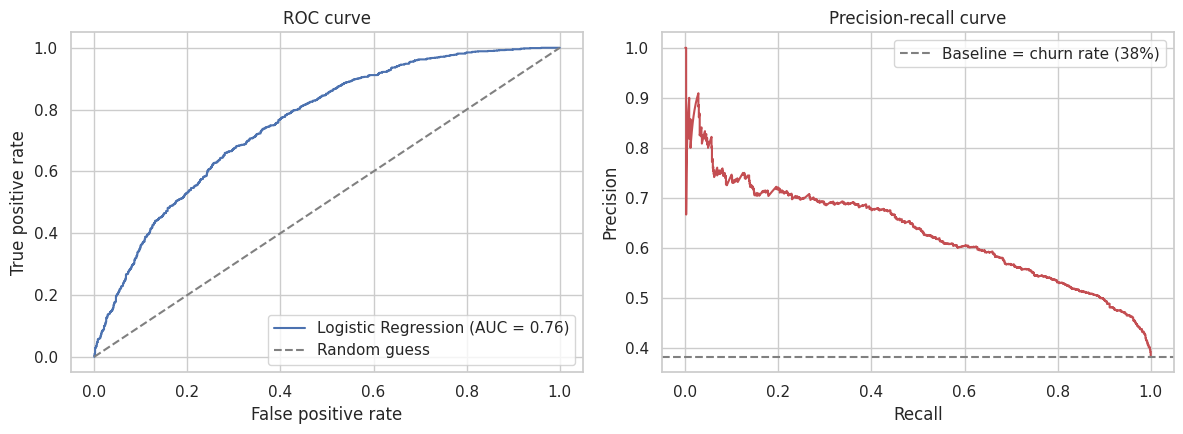

In [10]:
proba_test = final_model.predict_proba(X_test)[:, 1]          # churn probabilities on the future test period

fpr, tpr, _ = roc_curve(y_test, proba_test)                    # points of the ROC curve
prec, rec_, _ = precision_recall_curve(y_test, proba_test)     # points of the precision-recall curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, label=f"{final_name} (AUC = {roc_auc_score(y_test, proba_test):.2f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
axes[0].set_title("ROC curve"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend()
axes[1].plot(rec_, prec, color="#C44E52")
axes[1].axhline(y_test.mean(), linestyle="--", color="grey", label=f"Baseline = churn rate ({y_test.mean():.0%})")
axes[1].set_title("Precision-recall curve"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout()
plt.savefig(IMAGES / "15_churn_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Confusion matrix at the default threshold (0.5)

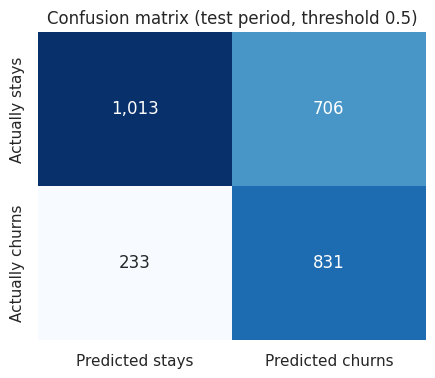

Precision 0.54 | Recall 0.78


In [11]:
pred_test = (proba_test >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred_test)                                    # rows = actual, columns = predicted
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted stays", "Predicted churns"], yticklabels=["Actually stays", "Actually churns"])
ax.set_title("Confusion matrix (test period, threshold 0.5)")
plt.savefig(IMAGES / "16_churn_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Precision {precision_score(y_test, pred_test):.2f} | Recall {recall_score(y_test, pred_test):.2f}")

**Evaluation:** at 0.5 the model catches most churners (high recall) but also flags many customers who would have stayed (precision ≈ 0.5). A retention team would **waste effort and discounts** on those. The threshold is a business decision, so instead of a fixed 0.5 I look at **ranking quality** next.

### 5.3 Lift table: if I only contact the riskiest customers, how many churners do I reach?
Sort customers from highest to lowest predicted risk and cut them into 10 equal groups (deciles). If the model is good, the top deciles contain far more churners than average.

In [12]:
lift = pd.DataFrame({"proba": proba_test, "churned": y_test.values})
lift["decile"] = pd.qcut(lift["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)   # 1 = highest risk
lift_table = lift.groupby("decile").agg(customers=("churned", "size"),
                                        actual_churn_rate=("churned", "mean"),
                                        avg_predicted=("proba", "mean"))
lift_table["share_of_all_churners"] = lift.groupby("decile")["churned"].sum() / lift["churned"].sum()      # how many churners are in this decile
lift_table["cumulative_churners_caught"] = lift_table["share_of_all_churners"].cumsum()
lift_table["lift_vs_average"] = lift_table["actual_churn_rate"] / lift["churned"].mean()
lift_table

,customers,actual_churn_rate,avg_predicted,share_of_all_churners,cumulative_churners_caught,lift_vs_average
decile,,,,,,
1,279,0.713,0.882,0.187,0.187,1.866
2,278,0.669,0.792,0.175,0.362,1.750
3,278,0.536,0.719,0.140,0.502,1.402
4,278,0.482,0.653,0.126,0.628,1.261
5,279,0.387,0.585,0.102,0.729,1.012
6,278,0.356,0.502,0.093,0.822,0.931
7,278,0.309,0.410,0.081,0.903,0.809
8,278,0.227,0.310,0.059,0.962,0.593
9,278,0.101,0.195,0.026,0.989,0.263


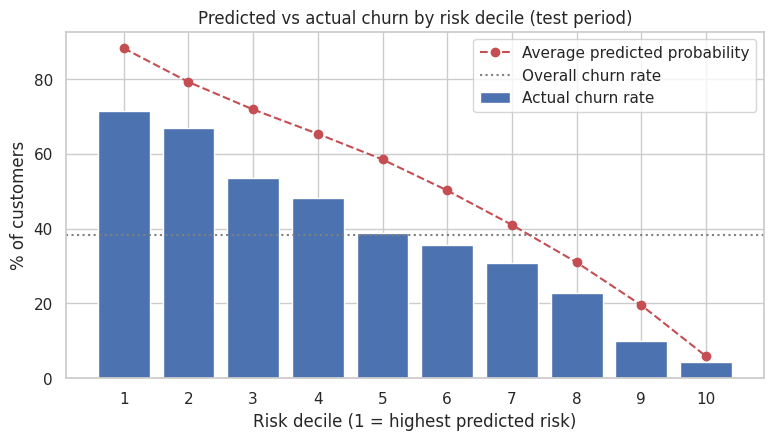

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(lift_table.index, lift_table["actual_churn_rate"] * 100, color="#4C72B0", label="Actual churn rate")
ax.plot(lift_table.index, lift_table["avg_predicted"] * 100, "o--", color="#C44E52", label="Average predicted probability")
ax.axhline(y_test.mean() * 100, color="grey", linestyle=":", label="Overall churn rate")
ax.set_xlabel("Risk decile (1 = highest predicted risk)")
ax.set_ylabel("% of customers")
ax.set_title("Predicted vs actual churn by risk decile (test period)")
ax.set_xticks(range(1, 11))
ax.legend()
plt.savefig(IMAGES / "17_churn_lift_deciles.png", dpi=150, bbox_inches="tight")
plt.show()

**Evaluation (reading the table):**
- The ranking works: the top decile has an actual churn rate of ~71% and the bottom decile only ~4% (overall 38%). Contacting the **top 30% of customers by risk reaches ~50% of all churners** (lift ~1.4-1.9x in those deciles).
- **Calibration warning:** the red dashed line (average predicted probability) sits **above** the bars: the model over-predicts churn in absolute terms. Reason: it was trained on the Jun–Sep period (51% churn) and tested on the busier Sep–Dec period (38% churn) — a seasonal shift. 
- Therefore I will use the output as a **risk ranking / score**, not as an exact probability. (If I deployed this I would retrain every period or recalibrate it.)

## Step 6 · What drives churn? (explainability)
Interviewers and business teams ask *why*. I use **permutation importance** (shuffle one feature on the test set and see how much AUC drops — a bigger drop = more important feature) plus the Logistic Regression coefficients.

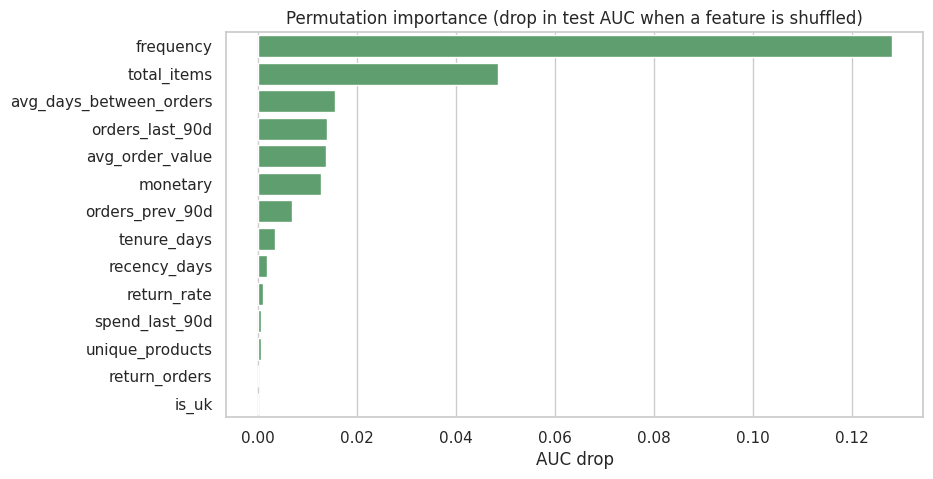

,feature,auc_drop,std
1,frequency,0.128,0.006
6,total_items,0.048,0.004
10,avg_days_between_orders,0.016,0.004
7,orders_last_90d,0.014,0.002
3,avg_order_value,0.014,0.002
2,monetary,0.013,0.003


In [14]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": FEATURES, "auc_drop": perm.importances_mean, "std": perm.importances_std})
         .sort_values("auc_drop", ascending=False))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=imp, y="feature", x="auc_drop", color="#55A868", ax=ax)
ax.set_title("Permutation importance (drop in test AUC when a feature is shuffled)")
ax.set_xlabel("AUC drop")
ax.set_ylabel("")
plt.savefig(IMAGES / "18_churn_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
imp.head(6)

In [15]:
# direction of each effect from the logistic regression (standardised coefficients: + raises churn risk, - lowers it)
if final_name == "Logistic Regression":
    coefs = pd.Series(final_model[-1].coef_[0], index=FEATURES).sort_values()
    print(coefs.round(2))

frequency                 -0.860
total_items               -0.510
orders_last_90d           -0.510
avg_order_value           -0.270
orders_prev_90d           -0.230
spend_last_90d            -0.080
unique_products           -0.020
is_uk                     -0.010
return_orders              0.090
recency_days               0.110
return_rate                0.130
tenure_days                0.150
avg_days_between_orders    0.300
monetary                   0.540
dtype: float64


**Insight (this differs from what I expected):**
- **Frequency (number of orders) is by far the most important feature** - shuffling it drops the AUC by ~0.13, almost 3x more than the next feature (`total_items`, ~0.05). Customers who have ordered many times are much less likely to leave.
- Recent-activity features (`orders_last_90d`, `avg_days_between_orders`) come next. **`recency_days` matters little** - I expected it to be top. Likely reason: I only kept customers active in the last 180 days, so recency has a narrow range, and `orders_last_90d` already carries similar information.
- Caution on the coefficients: `monetary` has a *positive* coefficient (more spend -> more churn?) which looks odd. It is because `monetary`, `frequency` and `total_items` are strongly correlated, so after accounting for frequency the leftover effect of `monetary` can flip sign. **I should not read single coefficients as cause and effect** - importance and direction are most reliable for the top feature (frequency, negative = protective).
- Country (`is_uk`), returns and `unique_products` add almost nothing.

## Step 7 · Final model: retrain on all labelled periods and score today's customers
**What:** the final model is re-fitted on **both** labelled periods (June and September cutoffs) so it has seen the most recent behaviour, then scores all customers as of **2011-12-10** (the last day of the data). 
**Why:** the evaluation above used a proper time-split; once I have chosen the approach, using all available labelled data for the final fit is standard practice.

In [16]:
# combine the two labelled periods (active customers only)
labelled = pd.concat([train, test])
X_all, y_all = prepare_features(labelled), labelled["churned"].astype(int)

# rebuild the chosen pipeline type and fit it on all labelled data
if final_name == "Logistic Regression":
    final_fit = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
else:
    final_fit = make_pipeline(SimpleImputer(strategy="median"),
                              RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1,
                                                     **{k.split("__")[1]: v for k, v in grid.best_params_.items()}))
final_fit.fit(X_all, y_all)

# customers as of the 'today' cutoff, active ones only (same rule as in training)
today = churn_all[churn_all["cutoff_date"] == "2011-12-10"].copy()
today = today[today["recency_days"] <= 180]
today["churn_risk"] = final_fit.predict_proba(prepare_features(today))[:, 1]       # risk score between 0 and 1

print(f"Scored {len(today):,} active customers")
print(today["churn_risk"].describe().round(3))

# save the model and the scores for notebook 04
joblib.dump(final_fit, MODELS / "churn_model.joblib")
today[["customer_id", "churn_risk"]].to_csv(PROCESSED / "churn_scores.csv", index=False)

Scored 3,471 active customers
count   3,471.000
mean        0.426
std         0.233
min         0.000
25%         0.237
50%         0.436
75%         0.616
max         0.996
Name: churn_risk, dtype: float64


## Summary & what I learned
- ✅ Framed churn **without leakage**: features before a cutoff, label in the 90 days after; built with a SQL stored procedure.
- ✅ **Time-based validation** (train on June cutoff, test on September cutoff) instead of an over-optimistic random split.
- ✅ Tested the population choice: restricting to *active* customers gave a lower but more honest AUC (~0.76).
- ✅ Compared a baseline, Logistic Regression and a tuned Random Forest with cross-validation; chose the **simpler model** because the forest did not win by a meaningful margin.
- ✅ Evaluated beyond one number: ROC/PR, confusion matrix, **lift by decile**, and found a **calibration shift** caused by seasonality.
- ✅ Explained the drivers with permutation importance.

### Limitations (honest list)
1. Only two labelled periods → a short history; seasonality is hard to learn. More cutoffs (rolling windows) would be better.
2. The model has no information about marketing activity, product categories or customer contact — real churn drivers beyond purchase behaviour.
3. Probabilities are not calibrated → use as a **ranking**.
4. Customers with no ID (22% of raw rows) are invisible to this model.

**Next → `04_retention_strategy.ipynb`:** combine churn risk + customer value + segments into a prioritised retention plan.